Let’s simulate the standard logistic growth model:
$$\frac{dx}{dt} = rx\left(1 - \frac{x}{K}\right)$$
This represents the growth of a population $x$ with an intrinsic growth rate r and a carrying capacity $K$.

In [23]:
import PyDSTool as dst
# The tool we will use for Dynamical Systems is PyDSTool https://github.com/robclewley/pydstool
import numpy as np
from matplotlib import pyplot as plt

In [24]:
# 1. Define the system

# Create a PyCont Instance
DSargs = dst.args(name="Logistic Growth")

# Define the parameters. These are different from "variables" and their values are determined prior to integration.

pars = {
    "r": 1,
    "K": 100
}

# Define the ODEs.
varspecs = {
    "x": "r*x*(1-x/K)"
}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics = {
    "x": 10,
}

DSargs.pars = pars
DSargs.varspecs = varspecs
DSargs.ics = ics

Computing trajectory...


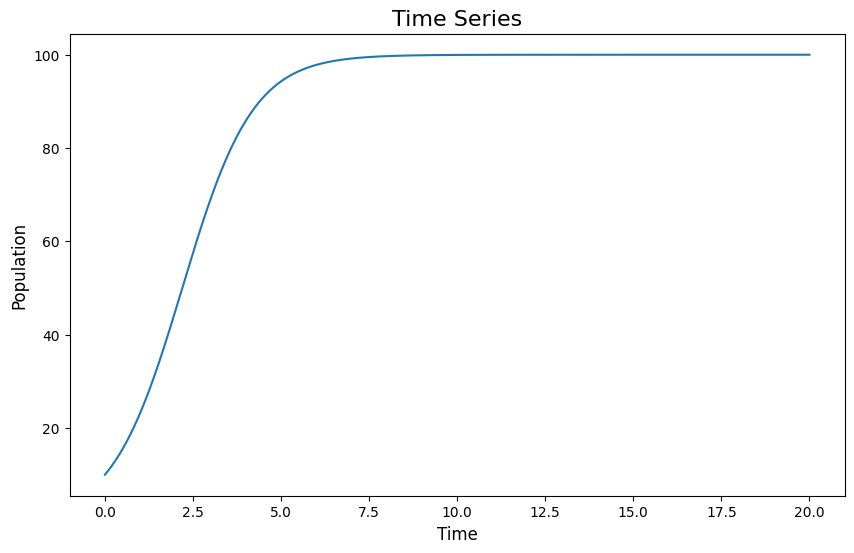

In [25]:
# 2. Compute the trajectory

# We choose which integrator to use, in this case it uses scipy' VODE
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)
# Define the range of time.
ode_sys.set(tdata=[0, 20])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

fig_1, ax_1 = plt.subplots(figsize=(10, 6))
ax_1.plot(points['t'], points['x'], label='x(t)')
ax_1.set_title('Time Series', fontsize=16)
ax_1.set_xlabel('Time', fontsize=12)
ax_1.set_ylabel('Population', fontsize=12)

plt.show()

__Task__: Now, let’s introduce a constant harvesting rate, $h$, to the model:
$$\frac{dx}{dt} = rx\left(1 - \frac{x}{K}\right) - h$$
We will find the critical harvesting rate, $h_{crit}$, by starting from a known equilibrium and continuing it
in the parameter $h$.

In [26]:
from PyDSTool.Toolbox import phaseplane as pp
# 1. Define the system

# Create a dst instance 
DSargs = dst.args(name="Logistic Growth with harvesting")

# Define the parameters. These are different from "variables" and their values are determined prior to integration.

pars = {
    "r": 1,
    "K": 100,
    "h": 0
}

# Define the ODEs.
varspecs = {
    "x": "r*x*(1-x/K) - h"
}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics = {
    "x": 10,
}

DSargs.pars = pars
DSargs.varspecs = varspecs
DSargs.ics = ics

In [27]:
# 2. Find Steady States
# Now before starting bifurcation analysis, we have to find a steady state. 
# This also means that we have to specify a domain for x where the SS can occur.

domain = {
    'x': [1e-4, 100],
}

DSargs.xdomain = domain

ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

fixed_points = pp.find_fixedpoints(ode_sys, n=16, eps=1e-6)

print(fixed_points)

({'x': array([0.])}, {'x': array([100.])})


In [28]:
# 3. Start Bifurcation Analysis
DSargs.ics = fixed_points[1]
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

PyCont = dst.ContClass(ode_sys)
PCargs = dst.args(name='EQ1', type='EP-C')  # Equilibrium curve
PCargs.freepars = ['h'] # Parameter we want to bifurcate against
PCargs.MaxNumPoints = 200 # Maximum number of points, continuation will stop if exceeds this limit
PCargs.MaxStepSize = 1 # Defines the maximum step size at each step of continuation, this is an important parameter and it will depend on the system
PCargs.MinStepSize = 1e-5 # Defines the minimum step size at each step of continuation. Depends on the system
PCargs.LocBifPoints = 'LP' # Specifies the points to look for. If 'all' is given, will find any bifurcation point
PCargs.SaveEigen = True
PCargs.SaveJacobian = True
PCargs.verbosity = 2
PyCont.newCurve(PCargs)

# Forward and backward continuation
PyCont['EQ1'].forward()
PyCont['EQ1'].backward()


Checking...
  |q| = 1.000000
  <p,q> = 1.000000
  |Aq| = 0.000000
  |transpose(A)p| = 0.000000

LP Point found 
0 : 
x  =  50.00000013187498
h  =  25.0

Eigenvalues = 

     (0.000000,0.000000)


a = 0.009999996238481875



Plotting diagram.


Text(0.5, 1.0, 'Bifurcation in (h, x) space')

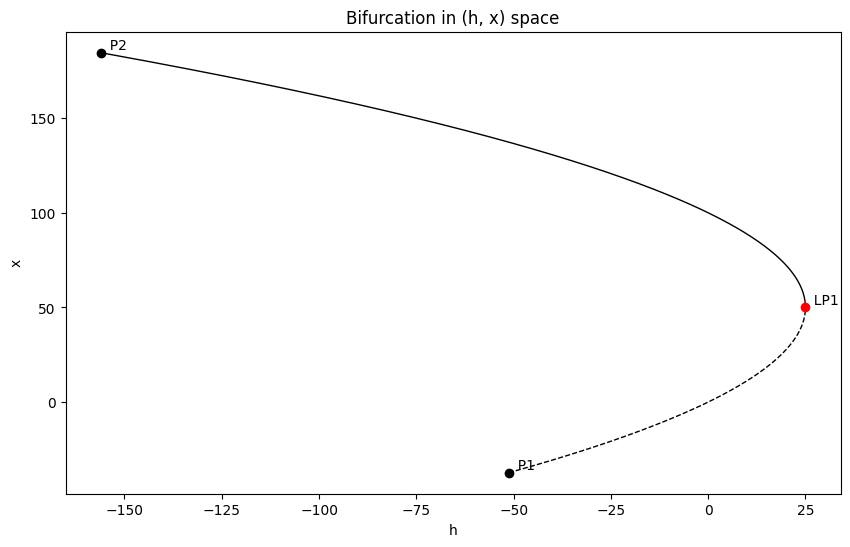

In [29]:
# 4. Plot the Results
print("Plotting diagram.")

plt.figure(figsize=(10, 6))
PyCont.display(('h', 'x'), stability=True)
plt.title("Bifurcation in (h, x) space")

In [20]:
# You can get information about the PyCont instance.
print("EQ1:")
PyCont['EQ1'].info() 

# To get detailed information at special points, you can use the getSpecialPoint method
print("LP1:")
PyCont['EQ1'].getSpecialPoint("LP1")

EQ1:
PyCont curve EQ1 (type EP-C)
Using model: Logistic Growth with harvesting

Model Info
---------- 

  Variables : x
  Parameters: r, K, h

Continuation Parameters
----------------------- 

name  =  EQ1
auxpars  =  []
freepars  =  ['h']
MaxNumPoints  =  200
MaxCorrIters  =  5
MaxTestIters  =  10
MaxStepSize  =  1
MinStepSize  =  1e-05
StepSize  =  1
VarTol  =  1e-06
FuncTol  =  1e-06
TestTol  =  0.0001
LocBifPoints  =  ['LP']
verbosity  =  2
ClosedCurve  =  50
SaveJacobian  =  True
SaveEigen  =  True
Corrector  =  <bound method Continuation._MoorePenrose of PyCont curve EQ1 (type EP-C)>
UseAuto  =  False
StopAtPoints  =  []
SPOut  =  None


Special Points
-------------- 

P1, P2, LP1
LP1:


h:  25.0
x:  50.00000013187498
Labels: EP ({'data': args (
 V = {'x': 1.0, 'h': -0.0},
 ds = 1,
 evals = [0.+0.j],
 evecs = [[1.]],
 jacx = [[0.]],
 jacp = [[-1.]]
), 'stab': 'N'})
Labels: LP ({'data': args (
 X = {'x': 50.00000013187498, 'h': 25.0},
 V = {'x': -1.0, 'h': 0.0},
 a = 0.009999996238481875,
 eigs = [0.+0.j]
), 'plot': No args defined, 'name': 'LP1'})